Używane urządzenie: cpu
Epoka 1/50 | Train Loss: 0.9226 | Val Loss: 3.4013
Epoka 2/50 | Train Loss: 0.7957 | Val Loss: 2.8711
Epoka 3/50 | Train Loss: 0.6780 | Val Loss: 2.3248
Epoka 4/50 | Train Loss: 0.5518 | Val Loss: 1.7122
Epoka 5/50 | Train Loss: 0.4056 | Val Loss: 1.0369
Epoka 6/50 | Train Loss: 0.2571 | Val Loss: 0.4952
Epoka 7/50 | Train Loss: 0.1999 | Val Loss: 0.3316
Epoka 8/50 | Train Loss: 0.1999 | Val Loss: 0.3724
Epoka 9/50 | Train Loss: 0.1934 | Val Loss: 0.4013
Epoka 10/50 | Train Loss: 0.1917 | Val Loss: 0.3774
Epoka 11/50 | Train Loss: 0.1900 | Val Loss: 0.3602
Epoka 12/50 | Train Loss: 0.1888 | Val Loss: 0.3584
Early stopping uruchomiony – przerywanie trenowania.


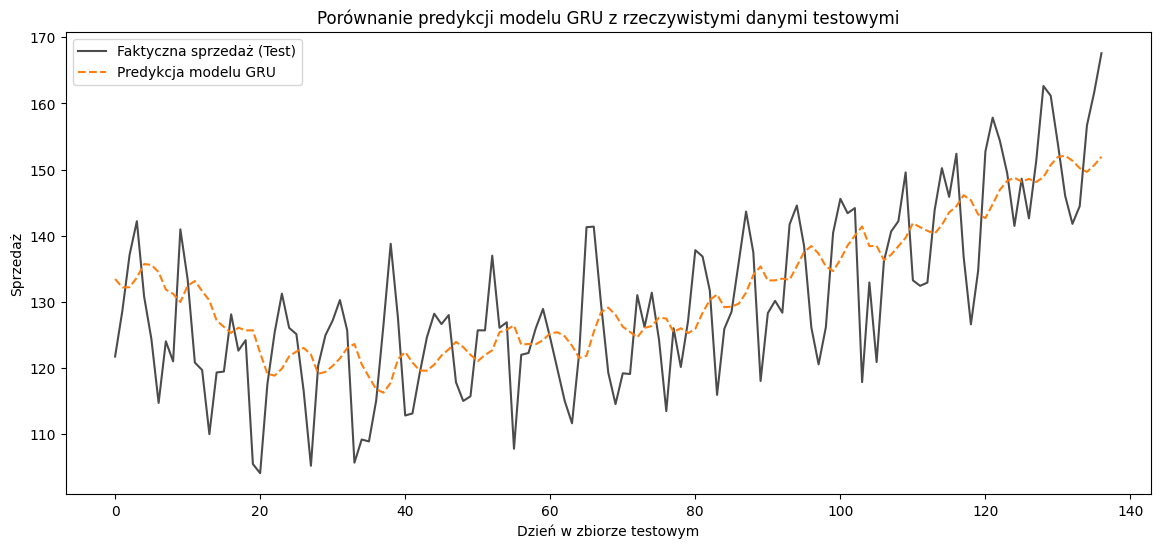

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Używane urządzenie: {device}")



n_days = 365 * 3
time = np.arange(n_days)

trend = 0.05 * time + 100
weekly_seasonality = 10 * np.sin(2 * np.pi * time / 7)
yearly_seasonality = 30 * np.sin(2 * np.pi * time / 365)
noise = np.random.normal(0, 5, n_days)

sales = trend + weekly_seasonality + yearly_seasonality + noise
sales = np.clip(sales, a_min=10, a_max=None)


train_size = int(0.7 * n_days)
val_size = int(0.15 * n_days)

train_data = sales[:train_size]
val_data = sales[train_size:train_size + val_size]
test_data = sales[train_size + val_size:]

mean_val = np.mean(train_data)
std_val = np.std(train_data)

train_scaled = (train_data - mean_val) / std_val
val_scaled = (val_data - mean_val) / std_val
test_scaled = (test_data - mean_val) / std_val


class TimeSeriesDataset(Dataset):
    def __init__(self, data, window_size):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.window_size = window_size

    def __len__(self):
        return len(self.data) - self.window_size

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.window_size]
        y = self.data[idx + self.window_size]
        return x.unsqueeze(-1), y.unsqueeze(-1)

WINDOW_SIZE = 28
BATCH_SIZE = 64

train_dataset = TimeSeriesDataset(train_scaled, WINDOW_SIZE)
val_dataset = TimeSeriesDataset(val_scaled, WINDOW_SIZE)
test_dataset = TimeSeriesDataset(test_scaled, WINDOW_SIZE)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


class ModelGRU(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=32, num_layers=1, output_dim=1):
        super(ModelGRU, self).__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

model = ModelGRU().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 50
patience = 5
best_val_loss = float('inf')
patience_counter = 0

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(x_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * x_batch.size(0)

    train_loss /= len(train_loader.dataset)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            outputs = model(x_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * x_batch.size(0)

    val_loss /= len(val_loader.dataset)

    print(f"Epoka {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), "best_gru_model.pth")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping uruchomiony – przerywanie trenowania.")
            break

model.load_state_dict(torch.load("best_gru_model.pth"))


model.eval()
predictions = []
actuals = []

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        outputs = model(x_batch)
        predictions.extend(outputs.cpu().numpy())
        actuals.extend(y_batch.numpy())

predictions = np.array(predictions) * std_val + mean_val
actuals = np.array(actuals) * std_val + mean_val

plt.figure(figsize=(14, 6))
plt.plot(actuals, label="Faktyczna sprzedaż (Test)", color="black", alpha=0.7)
plt.plot(predictions, label="Predykcja modelu GRU", color="tab:orange", linestyle="--")
plt.legend()
plt.title("Porównanie predykcji modelu GRU z rzeczywistymi danymi testowymi")
plt.xlabel("Dzień w zbiorze testowym")
plt.ylabel("Sprzedaż")
plt.show()